# RegExplain: E3 — DiCE gradient vs DiCE genetic vs greedy

Counterfactuals for **negative** test sequences, generated by three methods on the **same inputs** and the **same editable window** (central 41 bp, positions 30–70, 0-based), k = 4 per input. Queries are 30 random test sequences with label 0 that the explained model scores below 0.5 (seed 565). The explained model is E1 Tier 0 Model 1 (seed 565); transferability uses Model 2 (seed 566). Part B repeats the run on Tier 1 (CTCF/K562, dinucleotide-shuffled negatives) and, per the PDF, only **motif creation rate and transferability** are reported from it.

**Metrics (PDF 7.2):** % valid, sparsity, proximity (+ ΔGC), diversity, motif creation rate (FIMO, p < 1e-4, hit absent in the original), best-hit p-value drop, transferability, seconds per query.

**Design choices to state in the report**
- *Window:* all three methods may edit only positions 30–70 (PDF Section 6).
- *Validity* follows the PDF: a counterfactual counts if it is unique, differs from the input, and Model 1 scores it ≥ 0.5 (re-scored by us, not DiCE's label). "% valid" is unique valid counterfactuals divided by k = 4, so a method that returns duplicates or fewer than four loses validity.
- *Greedy, k = 4:* the PDF describes one greedy path. To get four, counterfactual j starts from the j-th best single substitution and then continues greedily until the label flips. This is our choice, not the PDF's.
- *FIMO:* memelite, run in a **separate Python process** because importing it next to torch crashed the Jupyter kernel in our environment. A numpy re-implementation of the same scan is kept as a cross-check (and as a fallback with `FIMO_BACKEND = "numpy"`). No FDR correction is applied. The motif matrix is never seen by the model or the generators; on Tier 0 it is the generating matrix, so it is not independent there (PDF Section 3), on Tier 1 it is.
- *Motif threshold:* p < 1e-4 is strict for the 7-bp Tier 0 motif (essentially the exact consensus) and looser for the longer CTCF motif, so creation rates are not directly comparable across tiers. We therefore also report creation at 1e-3 and 1e-2 and a baseline of random edits with the same sparsity.
- *Seeds:* 565 (queries, Model 1), 566 (Model 2). Versions are pinned in requirements.txt.

**How to run.** Run all cells from the top with `N_QUERIES = 30` (use 2 only as a smoke test, and then discard its outputs). Generated counterfactuals are cached in `e3_results/raw_*.json` and reused on re-runs; delete that folder to regenerate (about 45 minutes for both tiers). The gradient method needs about 18 s per query, but up to about 170 s when DiCE hits its iteration limit.

## 1. Imports and settings

In [ ]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
from pathlib import Path
from importlib.metadata import version
import time, json, warnings, tempfile, subprocess, sys
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
import dice_ml
from dice_ml.utils.helpers import DataTransfomer

warnings.filterwarnings("ignore")
SEED, N_QUERIES, K = 565, 30, 4 # use N_QUERIES = 2 only for a smoke test
METHODS = ["gradient", "genetic", "greedy"]
L, LO, HI = 101, 30, 70 # editable window = positions 30..70 inclusive (41 bp)
WIN = np.arange(LO, HI + 1)
cols = [f"p{i:03d}" for i in range(L)] # zero-padded: load-bearing (PDF Section 6)
mutable = [cols[i] for i in WIN]
P_SIG, P_LOOSE = 1e-4, 1e-2 # significance threshold; looser scan for p-value drop
FIMO_BACKEND = "memelite" # "memelite" (separate process) or "numpy"
torch.manual_seed(SEED); torch.set_num_threads(2)
out = Path("e3_results"); out.mkdir(exist_ok=True)
print({p: version(p) for p in ["torch", "dice-ml", "memelite", "numpy", "pandas"]})

{'torch': '2.14.1', 'dice-ml': '0.12', 'memelite': '0.5.0', 'numpy': '2.4.4', 'pandas': '3.0.2'}


## 2. Helpers: sequences, models, probabilities

In [ ]:
ACGT = "ACGT"
LUT = np.zeros(128, dtype=np.int64)
for i, c in enumerate(ACGT): LUT[ord(c)] = i
def to_ints(strs): return LUT[np.frombuffer("".join(strs).encode(), dtype=np.uint8)].reshape(len(strs), -1)
def to_str(a): return "".join(ACGT[i] for i in a)
def hamming(a, b): return sum(x != y for x, y in zip(a, b))
def gc(s): return (s.count("G") + s.count("C")) / len(s)

def load_cnn(path): # same architecture as E1; outputs logits
    cnn = nn.Sequential(nn.Conv1d(4, 64, 15, padding=7), nn.ReLU(), nn.MaxPool1d(2),
                        nn.Conv1d(64, 64, 7, padding=3), nn.ReLU(), nn.MaxPool1d(50),
                        nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    cnn.load_state_dict(torch.load(path, map_location="cpu", weights_only=True)["state_dict"])
    cnn.eval()
    for q in cnn.parameters(): q.requires_grad_(False)
    return cnn

def prob(cnn, ints): # (n, 101) int array -> P(bound), shape (n,)
    ints = np.asarray(ints, dtype=np.int64)
    with torch.no_grad():
        return np.concatenate([
            torch.sigmoid(cnn(torch.from_numpy(np.eye(4, dtype=np.float32)[ints[i:i + 1024]].transpose(0, 2, 1)))).numpy().ravel()
            for i in range(0, len(ints), 1024)])

## 3. The three counterfactual generators

**Greedy** (own code): from the current sequence, try all 41 × 3 = 123 single substitutions in the window, keep the best, repeat until P ≥ 0.5. Counterfactual j begins from the j-th best first move.

**DiCE gradient** follows PDF Section 6: zero-padded column names, `func="ohe-min-max"`, the column order read from the transformer, a wrapper that handles both flat vectors and batches, and `features_to_vary` restricted to the window.

**DiCE genetic** uses the raw categorical frame through an sklearn-style object and **`proximity_weight=0.0`**; `sparsity_weight` is left at its default.

In [ ]:
def greedy_cfs(cnn, seq, k=K):
    pos = np.repeat(WIN, 3)
    def moves(s): # all 123 single substitutions inside the window
        alt = (s[pos] + np.tile([1, 2, 3], len(WIN))) % 4
        m = np.repeat(s[None], len(pos), axis=0); m[np.arange(len(pos)), pos] = alt
        return m, prob(cnn, m)
    seq = np.asarray(seq, dtype=np.int64)
    m0, p0 = moves(seq); order = np.argsort(-p0)
    outs = []
    for j in range(k):
        s, pc, steps = m0[order[j]].copy(), p0[order[j]], 1
        while pc < 0.5 and steps < len(WIN):
            m, pm = moves(s); b = int(np.argmax(pm)); s, pc, steps = m[b], pm[b], steps + 1
        outs.append(to_str(s))
    return outs

class FlatWrapper(nn.Module): # PDF Section 6
    def __init__(self, cnn, enc):
        super().__init__(); self.cnn = cnn
        idx = {}
        for j, c in enumerate(enc):
            pos, base = c.rsplit("_", 1)
            idx[(int(pos[1:]), ACGT.index(base))] = j
        perm = np.array([[idx[(p, b)] for p in range(L)] for b in range(4)])
        self.register_buffer("perm", torch.tensor(perm.ravel()))
    def forward(self, x):
        x = x.float(); squeeze = (x.dim() == 1)
        if squeeze: x = x.unsqueeze(0)
        z = x[:, self.perm].reshape(-1, 4, L)
        o = torch.sigmoid(self.cnn(z)).reshape(-1, 1)
        return o[0] if squeeze else o

class SeqModel: # sklearn-style object for the genetic method
    def __init__(self, cnn): self.cnn = cnn
    def predict_proba(self, X):
        a = np.ascontiguousarray(X[cols].to_numpy().astype("U1"))
        p = prob(self.cnn, LUT[a.view(np.uint32).reshape(a.shape)])
        return np.column_stack([1 - p, p])
    def predict(self, X): return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def frame(ints, labels=None):
    df = pd.DataFrame([list(to_str(r)) for r in ints], columns=cols)
    if labels is not None: df["bound"] = np.asarray(labels).astype(int)
    return df

def build_dice(cnn, Xs, ys):
    df = frame(Xs, ys)
    d = dice_ml.Data(dataframe=df, continuous_features=[], outcome_name="bound")
    t = DataTransfomer("ohe-min-max"); t.feed_data_params(d); t.initialize_transform_func()
    enc = [c for c in t.transform(df.iloc[[0]]).columns if c != "bound"]
    wrapper = FlatWrapper(cnn, enc).eval()
    m_pyt = dice_ml.Model(model=wrapper, backend="PYT", func="ohe-min-max")
    m_sk = dice_ml.Model(model=SeqModel(cnn), backend="sklearn")
    return dict(df=df, t=t, enc=enc, wrapper=wrapper,
                grad=dice_ml.Dice(d, m_pyt, method="gradient"),
                gen=dice_ml.Dice(d, m_sk, method="genetic"))

def extract(cfs): # DiCE result -> list of sequence strings
    df = cfs.cf_examples_list[0].final_cfs_df
    return [] if df is None or len(df) == 0 else ["".join(r) for r in df[cols].astype(str).to_numpy()]

## 4. Tier 0: load models, pick the query sequences, set up DiCE

In [ ]:
t0a, t0b = Path("e1_results/tier0_seed565"), Path("e1_results/tier0_seed566")
d0 = np.load(t0a / "data.npz")
cnn1, cnn2 = load_cnn(t0a / "model.pt"), load_cnn(t0b / "model.pt")
X_test, y_test, X_train, y_train = d0["X_test"], d0["y_test"], d0["X_train"], d0["y_train"]
p1_test = prob(cnn1, X_test)

# Queries: random test sequences with label 0 that Model 1 scores as NEGATIVE (P < 0.5); same for all methods.
rng = np.random.default_rng(SEED)
neg = np.flatnonzero((p1_test < 0.5) & (y_test == 0))
qids0 = np.sort(rng.choice(neg, N_QUERIES, replace=False)); Xq0 = X_test[qids0]
pd.DataFrame({"test_index": qids0, "seq": [to_str(s) for s in Xq0], "p_model1": p1_test[qids0],
              "p_model2": prob(cnn2, Xq0)}).to_csv(out / "queries_tier0.csv", index=False)
print("Negative test sequences available:", len(neg), ", queries:", len(qids0))

# MEME file for the Tier 0 motif (same matrix as E1; background 0.3/0.2/0.2/0.3).
motif = np.array([[.10,.05,.05,.80],[.03,.03,.91,.03],[.91,.03,.03,.03],[.03,.03,.03,.91],
                  [.91,.03,.03,.03],[.88,.04,.04,.04],[.05,.05,.85,.05]])
meme0 = out / "tier0_GATA1.meme"
meme0.write_text("MEME version 4\n\nALPHABET= ACGT\n\nstrands: + -\n\nBackground letter frequencies\n"
                 "A 0.3 C 0.2 G 0.2 T 0.3\n\nMOTIF GATA1 GATA1_sim\n"
                 "letter-probability matrix: alength= 4 w= 7 nsites= 20 E= 0\n"
                 + "\n".join(" ".join(f"{v:.6f}" for v in row) for row in motif) + "\n")

dice0 = build_dice(cnn1, X_train[:2000], y_train[:2000])
print("Encoded columns:", len(dice0["enc"]), "(expected 404)")
tr = dice0["t"].transform(dice0["df"].iloc[:5])[dice0["enc"]].to_numpy(dtype=np.float32)
print("Wrapper vs CNN max |diff|:", float(np.abs(dice0["wrapper"](torch.from_numpy(tr)).numpy().ravel() - prob(cnn1, X_train[:5])).max()))

Negative test sequences available: 681 , queries: 30
Encoded columns: 404 (expected 404)
Wrapper vs CNN max |diff|: 0.0


### Optional: instrumented DiCE loss (PDF Section 6)

If DiCE returns nothing or odd results, print its loss components. A healthy run has a regularization term of the same order as the y-loss, and numbers that change across iterations; a regularization term about 1000× larger points to column-name collisions, and frozen numbers point to zeroed gradients. Set `DEBUG_LOSS = True` to probe **one** query (printing every 250th call), then the patch is removed.

In [ ]:
DEBUG_LOSS = False
if DEBUG_LOSS:
    from dice_ml.explainer_interfaces.dice_pytorch import DicePyTorch
    _orig, calls = DicePyTorch.compute_loss, {"n": 0}
    def _probe(self):
        o = _orig(self); calls["n"] += 1
        if calls["n"] % 250 == 1: print(calls["n"], "loss", float(self.loss), "yloss", float(self.yloss), "reg", float(self.regularization_loss))
        return o
    DicePyTorch.compute_loss = _probe
    try:
        q = pd.DataFrame([list(to_str(Xq0[0]))], columns=cols)
        _ = dice0["grad"].generate_counterfactuals(q, total_CFs=K, desired_class=1, features_to_vary=mutable)
    finally:
        DicePyTorch.compute_loss = _orig

## 5. Generate counterfactuals

Results are written to `e3_results/raw_<tier>.json` after every query, so an interrupted run resumes where it stopped. An error from DiCE is recorded, not hidden: the query then counts as "no counterfactual returned" and the message is kept in the JSON.

In [ ]:
def run_all(tag, cnn, dice, qids, Xq):
    path = out / f"raw_{tag}.json"
    raw = json.loads(path.read_text()) if path.exists() else {}
    for qi, seq in zip(qids, Xq):
        entry = raw.setdefault(str(int(qi)), {})
        s = to_str(seq); q = pd.DataFrame([list(s)], columns=cols)
        for m in METHODS:
            if m in entry: continue
            t = time.time(); err = None
            try:
                if m == "gradient":
                    seqs = extract(dice["grad"].generate_counterfactuals(q, total_CFs=K, desired_class=1, features_to_vary=mutable))
                elif m == "genetic":
                    seqs = extract(dice["gen"].generate_counterfactuals(q, total_CFs=K, desired_class=1,
                                                                        proximity_weight=0.0, features_to_vary=mutable))
                else:
                    seqs = greedy_cfs(cnn, seq)
            except Exception as e:
                seqs, err = [], f"{type(e).__name__}: {e}"
            entry[m] = {"cfs": seqs, "sec": time.time() - t, "error": err}
        path.write_text(json.dumps(raw))
        print(f"query {int(qi)}: " + " , ".join(f"{m}: {len(entry[m]['cfs'])} CFs, {entry[m]['sec']:.1f}s" for m in METHODS))
    errs = {m: sum(bool(raw[k][m]["error"]) for k in raw if m in raw[k]) for m in METHODS}
    print("Queries where DiCE raised an error:", errs)
    return raw

raw0 = run_all("tier0", cnn1, dice0, qids0, Xq0)

100%|████████████████████████████████████████████| 1/1 [00:52<00:00, 52.24s/it]


Diverse Counterfactuals found! total time taken: 00 min 49 sec


100%|████████████████████████████████████████████| 1/1 [00:05<00:00,  5.77s/it]


query 0: gradient: 4 CFs, 52.3s , genetic: 4 CFs, 5.8s , greedy: 4 CFs, 0.4s


100%|████████████████████████████████████████████| 1/1 [00:19<00:00, 19.26s/it]


Diverse Counterfactuals found! total time taken: 00 min 17 sec


... (110 outputs left out)

100%|████████████████████████████████████████████| 1/1 [00:24<00:00, 24.72s/it]


Diverse Counterfactuals found! total time taken: 00 min 23 sec


100%|████████████████████████████████████████████| 1/1 [00:03<00:00,  3.68s/it]


query 1495: gradient: 4 CFs, 24.7s , genetic: 4 CFs, 3.7s , greedy: 4 CFs, 0.2s
Queries where DiCE raised an error: {'gradient': 0, 'genetic': 0, 'greedy': 0}


## 6. Metrics

**FIMO.** `scan_memelite` writes the sequences to a temporary FASTA and runs memelite in a **separate Python process** (a small worker script written below), so memelite/numba never share a process with torch. `scan_np` is an independent numpy implementation of the same scan: log-odds against the motif file's background (pseudocount 1e-4), exact p-values from the score distribution, forward and optionally reverse strand. Hits are 0-based with exclusive `end`. The two are compared on our own sequences in the cross-check cells; p-values differ slightly (memelite bins scores), so hits right at the cutoff can differ. No FDR correction is applied.

A hit is **created** if it is significant (p < 1e-4) in the counterfactual at a (start, strand) where the original has no significant hit. Tier 0 scans the forward strand only (the motif was planted that way); Tier 1 scans both strands. The best-hit p-value drop is `log10(p_original) - log10(p_counterfactual)` (positive = stronger hit after the edit), uses a looser scan (p < 1e-2), and is **censored** at 1e-2 when no hit exists.

In [ ]:
WORKER = Path("fimo_worker.py")
WORKER.write_text("""import sys, pandas as pd
from memelite import fimo
meme, fasta, thr, both, outp = sys.argv[1:6]
res = fimo(meme, fasta, threshold=float(thr), reverse_complement=(both == "1"))
res = pd.concat(res if isinstance(res, list) else [res], ignore_index=True)
res.to_csv(outp, index=False)
""")
HIT_COLS = ["seq", "start", "end", "strand", "p", "matched"]

def scan_memelite(strs, meme, threshold, both_strands):
    with tempfile.TemporaryDirectory() as tmp:
        fa, o = Path(tmp) / "s.fa", Path(tmp) / "o.csv"
        fa.write_text("".join(f">s{i}\n{s}\n" for i, s in enumerate(strs)))
        r = subprocess.run([sys.executable, str(WORKER), str(meme), str(fa), str(threshold),
                            "1" if both_strands else "0", str(o)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"memelite worker failed (code {r.returncode}):\n{r.stderr[-1500:]}")
        res = pd.read_csv(o)
    if len(res) == 0: return pd.DataFrame(columns=HIT_COLS)
    pcol = [c for c in res.columns if c.lower().replace("_", "-") in ("p-value", "pvalue")][0]
    res = res.rename(columns={pcol: "p"})
    res["seq"] = res["sequence_name"].astype(str).str.lstrip("s").astype(int)
    res["matched"] = res["matched_sequence"] if "matched_sequence" in res else ""
    return res[HIT_COLS].astype({"p": float})

def read_meme(path):
    lines = Path(path).read_text().splitlines()
    bg = {c: 0.25 for c in ACGT}
    for i, l in enumerate(lines):
        if l.startswith("Background letter"):
            t = lines[i + 1].split(); bg = {t[j]: float(t[j + 1]) for j in range(0, 8, 2)}
        if l.startswith("letter-probability matrix"):
            w = int(l.split("w=")[1].split()[0])
            P = np.array([[float(x) for x in lines[i + 1 + r].split()[:4]] for r in range(w)])
            break
    return P, np.array([bg[c] for c in ACGT])

def pvalue_tail(S, bg, scale=100): # exact score distribution by dynamic programming
    Si = np.round(S * scale).astype(int)
    dist = np.ones(1)
    for j in range(len(Si)):
        mn = Si[j].min(); new = np.zeros(len(dist) + Si[j].max() - mn)
        for b in range(4):
            sh = Si[j, b] - mn; new[sh:sh + len(dist)] += bg[b] * dist
        dist = new
    return Si.min(1).sum(), np.cumsum(dist[::-1])[::-1] # tail[k] = P(score >= lo + k)

def scan_np(strs, meme, threshold, both_strands):
    P, bg = read_meme(meme); w = len(P)
    P = (P + 1e-4) / (P + 1e-4).sum(1, keepdims=True)
    S = np.log2(P / bg)
    lo, tail = pvalue_tail(S, bg)
    ints = to_ints(list(strs)); n, Lq = ints.shape; nw = Lq - w + 1
    rows = []
    for strand in (["+", "-"] if both_strands else ["+"]):
        x = ints if strand == "+" else 3 - ints[:, ::-1]
        sc = sum(S[j][x[:, j:j + nw]] for j in range(w))
        k = np.round(sc * 100).astype(int) - lo
        p = np.where(k > len(tail) - 1, 0.0, tail[np.clip(k, 0, len(tail) - 1)])
        for i, pos in zip(*np.nonzero(p <= threshold)):
            st = pos if strand == "+" else Lq - w - pos
            rows.append((int(i), int(st), int(st) + w, strand, float(p[i, pos]), strs[i][st:st + w]))
    return pd.DataFrame(rows, columns=HIT_COLS)

def scan(strs, meme, threshold, both_strands):
    return (scan_memelite if FIMO_BACKEND == "memelite" else scan_np)(strs, meme, threshold, both_strands)

def crosscheck(strs, meme, both_strands, thr=P_SIG):
    a, b = scan_np(strs, meme, thr, both_strands), scan_memelite(strs, meme, thr, both_strands)
    key = lambda d: set(zip(d.seq, d.start, d.strand))
    ka, kb = key(a), key(b)
    print(f"hits at p<={thr:g}: numpy {len(ka)} | memelite {len(kb)} | both {len(ka & kb)} | numpy only {len(ka - kb)} | memelite only {len(kb - ka)}")
    return a, b

In [ ]:
def evaluate(raw, qids, Xq, cnn1, cnn2, meme, both_strands):
    orig = {int(q): to_str(s) for q, s in zip(qids, Xq)}
    rows = []
    for q, s in orig.items():
        for m in METHODS:
            seen = set()
            for j, c in enumerate(raw[str(q)][m]["cfs"]):
                if c in seen or c == s: continue # unique, and not the input itself
                seen.add(c); rows.append(dict(method=m, query=q, cf=j, seq=c, orig=s))
    cf = pd.DataFrame(rows)
    cf["p1"], cf["p2"] = prob(cnn1, to_ints(list(cf.seq))), prob(cnn2, to_ints(list(cf.seq)))
    cf["valid"], cf["transfers"] = cf.p1 >= 0.5, cf.p2 >= 0.5
    cf["p_orig"] = prob(cnn1, to_ints(list(cf.orig)))
    cf["d_H"] = [hamming(a, b) for a, b in zip(cf.seq, cf.orig)]
    cf["win_frac"], cf["norm_dH"] = cf.d_H / len(WIN), cf.d_H / L
    cf["proximity"] = 1 - cf.norm_dH
    cf["dGC"] = [gc(a) - gc(b) for a, b in zip(cf.seq, cf.orig)]
    uniq = sorted(set(orig.values()) | set(cf.seq)); ix = {s: i for i, s in enumerate(uniq)}
    sig, loose = scan(uniq, meme, P_SIG, both_strands), scan(uniq, meme, P_LOOSE, both_strands)
    print("FIMO backend:", FIMO_BACKEND)
    hits = {}
    for r in sig.itertuples(): hits.setdefault(r.seq, {})[(int(r.start), r.strand)] = (int(r.start), int(r.end), r.p, r.matched)
    best = loose.groupby("seq")["p"].min().to_dict()
    new, drop = [], []
    for r in cf.itertuples():
        h_cf, h_o = hits.get(ix[r.seq], {}), hits.get(ix[r.orig], {})
        new.append([v for k, v in h_cf.items() if k not in h_o])
        drop.append(np.log10(best.get(ix[r.orig], P_LOOSE)) - np.log10(best.get(ix[r.seq], P_LOOSE)))
    cf["new_hits"], cf["created"], cf["log10p_drop"] = new, [len(n) > 0 for n in new], drop
    return cf

def diversity(g): # mean pairwise Hamming among valid CFs of one query
    s = list(g.seq); pairs = [(i, j) for i in range(len(s)) for j in range(i + 1, len(s))]
    return np.mean([hamming(s[i], s[j]) for i, j in pairs]) if pairs else np.nan

def summarize(cf, raw, qids):
    def iqr(x, f="{:.1f}"): a, b, c = np.percentile(x, [50, 25, 75]); return f"{f.format(a)} ({f.format(b)}-{f.format(c)})"
    res = {}
    for m in METHODS:
        v = cf[(cf.method == m) & cf.valid]
        nv = [int(((cf.method == m) & (cf["query"] == int(q)) & cf.valid).sum()) for q in qids]
        div = [diversity(g) for _, g in v.groupby("query")]
        secs = [raw[str(int(q))][m]["sec"] for q in qids]
        res[m] = {
            "CFs returned per query (mean of k)": f"{np.mean([len(raw[str(int(q))][m]['cfs']) for q in qids]):.2f}",
            "% valid CFs (unique in target class of k)": f"{100 * np.mean(nv) / K:.0f}",
            "queries with no valid CF": f"{sum(n == 0 for n in nv)} / {len(nv)}",
            "sparsity: median edits (IQR)": iqr(v.d_H) if len(v) else "-",
            "fraction of 41 bp window rewritten": f"{100 * v.win_frac.median():.0f}%" if len(v) else "-",
            "normalised d_H / L (median)": f"{v.norm_dH.median():.3f}" if len(v) else "-",
            "proximity 1 - d_H/L (median)": f"{v.proximity.median():.3f}" if len(v) else "-",
            "change in GC (median, IQR)": iqr(v.dGC, "{:+.3f}") if len(v) else "-",
            "diversity: mean pairwise Hamming": f"{np.nanmean(div):.1f}" if len(div) and not np.all(np.isnan(div)) else "-",
            "motif creation rate": f"{100 * v.created.mean():.0f}%  ({int(v.created.sum())}/{len(v)})" if len(v) else "-",
            "best hit p drop, log10 (median, IQR)": iqr(v.log10p_drop) if len(v) else "-",
            "transferability to 2nd model": f"{100 * v.transfers.mean():.0f}%" if len(v) else "-",
            "seconds per query (median / mean)": f"{np.median(secs):.1f} / {np.mean(secs):.1f}"}
    return pd.DataFrame(res)

In [ ]:
cf0 = evaluate(raw0, qids0, Xq0, cnn1, cnn2, meme0, both_strands=False)
summary0 = summarize(cf0, raw0, qids0)
cf0.drop(columns=["new_hits"]).to_csv(out / "counterfactuals_tier0.csv", index=False)
summary0.to_csv(out / "summary_tier0.csv"); print(summary0.to_string())

FIMO backend: memelite
                                                         gradient                 genetic                  greedy
CFs returned per query (mean of k)                           3.70                    4.00                    4.00
% valid CFs (unique in target class of k)                      90                     100                      81
queries with no valid CF                                   0 / 30                  0 / 30                  0 / 30
sparsity: median edits (IQR)                       7.0 (4.0-10.0)        26.0 (24.0-27.0)           2.0 (2.0-2.0)
fraction of 41 bp window rewritten                            17%                     63%                      5%
normalised d_H / L (median)                                 0.069                   0.257                   0.020
proximity 1 - d_H/L (median)                                0.931                   0.743                   0.980
change in GC (median, IQR)                 +0.000 (-0.010-+0.010)

In [ ]:
# Cross-check: numpy scan vs memelite on the query sequences and every counterfactual (forward strand, Tier 0).
_ = crosscheck([to_str(s) for s in Xq0] + list(cf0.seq), meme0, both_strands=False)

hits at p<=0.0001: numpy 162 | memelite 162 | both 162 | numpy only 0 | memelite only 0


### Threshold sensitivity, random-edit baseline, and uncertainty

Three additions beyond the PDF's table, because the strict p < 1e-4 cutoff and 30 queries make the headline numbers easy to over-read:
- **Creation at 1e-4 / 1e-3 / 1e-2** next to a **random-edit baseline** (the same number of random substitutions inside the window, per counterfactual). A creation rate is only meaningful relative to what random edits produce at the same threshold.
- **Transferability split by whether a motif was created.**
- **Bootstrap 95% intervals that resample queries**, not counterfactuals: the four counterfactuals from one query are not independent.

In [ ]:
def creation_at(cf, meme, thr, both):
    uniq = sorted(set(cf.orig) | set(cf.seq)); ix = {s: i for i, s in enumerate(uniq)}
    hits = {}
    for r in scan(uniq, meme, thr, both).itertuples(): hits.setdefault(r.seq, set()).add((r.start, r.strand))
    return np.array([len(hits.get(ix[s], set()) - hits.get(ix[o], set())) > 0 for s, o in zip(cf.seq, cf.orig)])

def random_baseline(cf, meme, both, thr, seed=0): # same number of edits, random positions in the window
    rg = np.random.default_rng(seed); seqs = []
    for o, d in zip(cf.orig, cf.d_H):
        s = list(o)
        for p in rg.choice(WIN, d, replace=False): s[p] = rg.choice([b for b in ACGT if b != s[p]])
        seqs.append("".join(s))
    return creation_at(cf.assign(seq=seqs), meme, thr, both)

def boot_ci(v, col, n=2000, seed=0): # resample queries, not counterfactuals
    rg = np.random.default_rng(seed); res = {}
    for m in METHODS:
        g = {q: d[col].to_numpy() for q, d in v[v.method == m].groupby("query")}; qs = list(g)
        est = [np.concatenate([g[q] for q in rg.choice(qs, len(qs))]).mean() for _ in range(n)]
        res[m] = (v[v.method == m][col].mean(), *np.percentile(est, [2.5, 97.5]))
    return pd.DataFrame(res, index=["est", "lo", "hi"]).round(2)

def tier_checks(cf, raw, meme, both):
    print("CFs returned vs unique, per method:", {m: (sum(len(raw[k][m]["cfs"]) for k in raw), int((cf.method == m).sum())) for m in METHODS})
    print("fraction of unique CFs that are valid:\n", cf.groupby("method").valid.mean().round(2).to_dict())
    v = cf[cf.valid].copy()
    for thr in [1e-4, 1e-3, 1e-2]:
        v[f"obs_{thr:g}"] = creation_at(v, meme, thr, both)
        v[f"rand_{thr:g}"] = random_baseline(v, meme, both, thr)
    print("\nmotif creation by threshold (obs_ = counterfactuals, rand_ = same-sparsity random edits):")
    print(v.groupby("method")[[c for c in v if c.startswith(("obs_", "rand_"))]].mean().round(2))
    print("\ntransferability by motif created:"); print(v.groupby(["method", "created"]).transfers.agg(["mean", "size"]).round(2))
    print("\ncreation rate, 95% CI over queries:\n", boot_ci(v, "created"))
    print("\ntransferability, 95% CI over queries:\n", boot_ci(v, "transfers"))
    return v

v0 = tier_checks(cf0, raw0, meme0, False)

CFs returned vs unique, per method: {'gradient': (111, 108), 'genetic': (120, 120), 'greedy': (120, 97)}
fraction of unique CFs that are valid:
 {'genetic': 1.0, 'gradient': 1.0, 'greedy': 1.0}

motif creation by threshold (obs_ = counterfactuals, rand_ = same-sparsity random edits):
          obs_0.0001  rand_0.0001  obs_0.001  rand_0.001  obs_0.01  rand_0.01
method                                                                       
genetic         0.48          0.0       0.71        0.02      0.99       0.34
gradient        0.77          0.0       0.94        0.04      0.67       0.21
greedy          0.20          0.0       0.79        0.00      0.68       0.10

transferability by motif created:
                  mean  size
method   created            
genetic  False    0.79    63
         True     1.00    57
gradient False    0.80    25
         True     1.00    83
greedy   False    0.88    78
         True     1.00    19

creation rate, 95% CI over queries:
      gradient  genet

### Sparsity is not correctness

The PDF's central claim is that the sparsest counterfactual is not the most correct one. Sparsity is the number of edits; correctness is whether the edits wrote the TF's real motif. This plot puts the two side by side, per method.

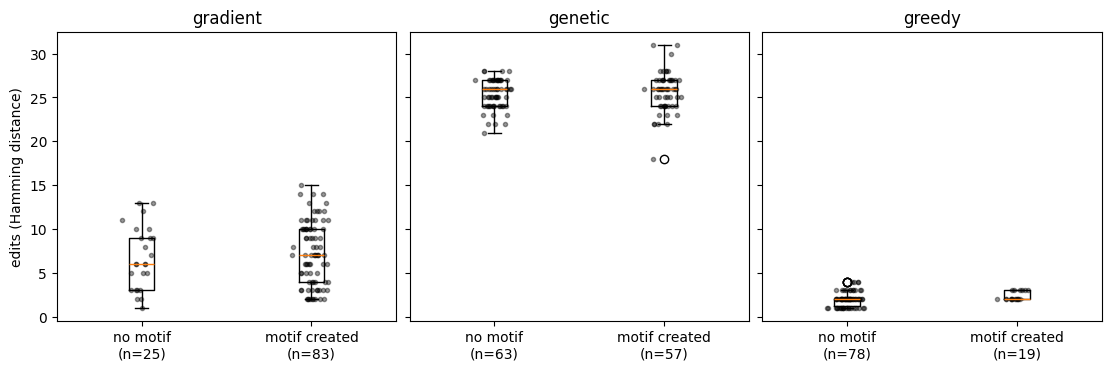

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, m in zip(axes, METHODS):
    v = cf0[(cf0.method == m) & cf0.valid]
    groups = [v[~v.created].d_H, v[v.created].d_H]
    ax.boxplot(list(groups), tick_labels=[f"no motif\n(n={len(groups[0])})", f"motif created\n(n={len(groups[1])})"])
    for i, g in enumerate(groups, 1): ax.plot(np.random.default_rng(0).normal(i, 0.05, len(g)), g, ".", alpha=.4, color="k")
    ax.set(title=m)
axes[0].set_ylabel("edits (Hamming distance)")
fig.savefig(out / "sparsity_vs_motif_tier0.png", dpi=200); plt.show()

## 7. Alignments (randomly chosen, including failures)

Queries are drawn with a fixed seed **without looking at the results**, one counterfactual per method (the first valid one). `^` marks an edited position and `[---]` a FIMO hit present in the counterfactual and absent in the original. Counterfactuals with no created hit are shown as they are: they are part of the answer.

In [ ]:
def alignment(r, lo=28, hi=75):
    o, c, w = r.orig, r.seq, hi - lo
    ruler = [" "] * w
    for i in range(lo, hi):
        if i % 10 == 0 and i - lo + 2 <= w:
            for k, ch in enumerate(str(i)): ruler[i - lo + k] = ch
    fim = [" "] * w
    for (st, en, p, mt) in r.new_hits:
        a, b = max(st, lo) - lo, min(en, hi) - lo
        if b > a: fim[a:b] = list("[" + "-" * (b - a - 2) + "]" if b - a >= 2 else "|")
    ed = "".join("^" if o[i] != c[i] else " " for i in range(lo, hi))
    lines = [f"{r.method}, {r.d_H} edits, P(bound): {r.p_orig:.3f} -> {r.p1:.3f}, second model: {r.p2:.3f}",
             "pos      " + "".join(ruler), "original " + o[lo:hi], "counterf " + c[lo:hi],
             "edits    " + ed, "FIMO hit " + "".join(fim)]
    for (st, en, p, mt) in r.new_hits: lines.append(f"         created {mt or c[st:en]} at {st}-{en}, p = {p:.1e}")
    if not r.new_hits: lines.append("         no new FIMO hit")
    return "\n".join(lines)

def show_alignments(cf, qids, n=3, seed=SEED, fname=None):
    rg = np.random.default_rng(seed); txt = []
    for q in rg.choice(qids, min(n, len(qids)), replace=False):
        txt.append(f"query (test index) {int(q)}")
        for m in METHODS:
            g = cf[(cf["query"] == int(q)) & (cf.method == m) & cf.valid]
            txt.append(alignment(next(g.head(1).itertuples())) if len(g) else f"{m}: no valid counterfactual")
            txt.append("")
    s = "\n".join(txt); print(s)
    if fname: (out / fname).write_text(s)
show_alignments(cf0, qids0, fname="alignments_tier0.txt")

query (test index) 784
gradient, 3 edits, P(bound): 0.088 -> 0.890, second model: 0.960
pos        30        40        50        60        70   
original TATTACTTTAGAATAATGTGTTTTGCGGGCTTATCGCCTCATAGATA
counterf TAAGACTTTAGAATAATGTGTTTTGCGGGCTTATCGCCTCATTGATA
edits      ^^                                      ^    
FIMO hit                                                
         no new FIMO hit

genetic, 24 edits, P(bound): 0.088 -> 0.834, second model: 0.811
pos        30        40        50        60        70   
original TATTACTTTAGAATAATGTGTTTTGCGGGCTTATCGCCTCATAGATA
counterf TACTCCTCTGTAATAAGTCCGGTTAGGATTTAGGCTGATGAGAGATA
edits      ^ ^  ^ ^^     ^^^^^^  ^^ ^^^ ^^^ ^^^ ^ ^     
FIMO hit                                                
         no new FIMO hit

greedy, 1 edits, P(bound): 0.088 -> 0.560, second model: 0.540
pos        30        40        50        60        70   
original TATTACTTTAGAATAATGTGTTTTGCGGGCTTATCGCCTCATAGATA
counterf TATTACTTTAGAATAATGTGTTTTGCGGGCTTATCGCCT

## 8. Part B: Tier 1 (CTCF/K562) transfer check

Same pipeline, same window, same k, with the E1 Tier 1 models (seed 565 explained, seed 566 for transferability). **Report only motif creation rate and transferability** from this table (PDF Section 3). Both seeds use the same data and differ in initialization and batch order only, so transferability here is weaker evidence than on Tier 0. FIMO scans both strands for CTCF.

In [ ]:
sys.path.insert(0, str(Path.cwd()))
from tier1_loader import load_tier1
tr1, va1, te1 = load_tier1("tier1_CTCF_K562.npz", negatives="dinuc")
cnn1b = load_cnn("e1_results/tier1_seed565/model.pt"); cnn2b = load_cnn("e1_results/tier1_seed566/model.pt")
Xte1, yte1 = te1; p1b = prob(cnn1b, Xte1)
rg = np.random.default_rng(SEED)
neg1 = np.flatnonzero((p1b < 0.5) & (yte1 == 0))
qids1 = np.sort(rg.choice(neg1, N_QUERIES, replace=False)); Xq1 = Xte1[qids1]
sub = np.sort(rg.choice(len(tr1[1]), 2000, replace=False)) # mixed-class sample defines DiCE's feature space
dice1 = build_dice(cnn1b, tr1[0][sub], tr1[1][sub])
print("Tier 1 negative test sequences scored negative:", len(neg1), ", queries:", len(qids1))
pd.DataFrame({"test_index": qids1, "seq": [to_str(s) for s in Xq1], "p_model1": p1b[qids1],
              "p_model2": prob(cnn2b, Xq1)}).to_csv(out / "queries_tier1.csv", index=False)
raw1 = run_all("tier1", cnn1b, dice1, qids1, Xq1)

Tier 1 negative test sequences scored negative: 3463 , queries: 30


100%|████████████████████████████████████████████| 1/1 [00:24<00:00, 24.28s/it]


Diverse Counterfactuals found! total time taken: 00 min 23 sec


100%|████████████████████████████████████████████| 1/1 [00:03<00:00,  3.65s/it]


query 7: gradient: 4 CFs, 24.3s , genetic: 4 CFs, 3.7s , greedy: 4 CFs, 0.5s


100%|████████████████████████████████████████████| 1/1 [00:21<00:00, 21.57s/it]


... (111 outputs left out)

100%|████████████████████████████████████████████| 1/1 [00:21<00:00, 21.37s/it]


Diverse Counterfactuals found! total time taken: 00 min 20 sec


100%|████████████████████████████████████████████| 1/1 [00:03<00:00,  3.93s/it]


query 7429: gradient: 4 CFs, 21.4s , genetic: 4 CFs, 3.9s , greedy: 4 CFs, 0.7s
Queries where DiCE raised an error: {'gradient': 0, 'genetic': 0, 'greedy': 0}


In [ ]:
MEME1 = "tier1_CTCF_K562.meme"
cf1 = evaluate(raw1, qids1, Xq1, cnn1b, cnn2b, MEME1, both_strands=True)
summary1 = summarize(cf1, raw1, qids1)
cf1.drop(columns=["new_hits"]).to_csv(out / "counterfactuals_tier1.csv", index=False)
summary1.to_csv(out / "summary_tier1.csv"); print(summary1.to_string())
print("\nRequired for Tier 1:"); print(summary1.loc[["motif creation rate", "transferability to 2nd model"]].to_string())
_ = crosscheck([to_str(s) for s in Xq1] + list(cf1.seq), MEME1, both_strands=True)
v1 = tier_checks(cf1, raw1, MEME1, True)
show_alignments(cf1, qids1, fname="alignments_tier1.txt")

FIMO backend: memelite
                                                         gradient                 genetic                  greedy
CFs returned per query (mean of k)                           3.97                    4.00                    4.00
% valid CFs (unique in target class of k)                      99                     100                      86
queries with no valid CF                                   0 / 30                  0 / 30                  0 / 30
sparsity: median edits (IQR)                      11.0 (7.0-14.0)        25.0 (24.0-26.0)           2.0 (2.0-3.0)
fraction of 41 bp window rewritten                            27%                     61%                      5%
normalised d_H / L (median)                                 0.109                   0.248                   0.020
proximity 1 - d_H/L (median)                                0.891                   0.752                   0.980
change in GC (median, IQR)                 -0.010 (-0.020-+0.010)

## 9. Results

**Validity and yield.** Every query received counterfactuals from all three methods, DiCE raised no errors, and every unique counterfactual was a valid one (re-scored by Model 1). "% valid" is therefore a yield measure. Unique valid counterfactuals per query (of k = 4) were 90% (gradient), 100% (genetic) and 81% (greedy) on Tier 0, and 99%, 100% and 86% on Tier 1. Greedy loses yield to duplicates: its four paths often end in the same sequence (Tier 0: 120 returned, 97 unique). Gradient returned fewer than four on 7 of 30 Tier 0 queries (335, 527, 569, 578, 726, 1035, 1334) and on one Tier 1 query; these took 157–214 s against a median of 22.6 s, which is probably DiCE reaching its iteration limit.

**Sparsity is not correctness (Tier 0).** Creation is the fraction of valid counterfactuals with a new FIMO hit; the random-edit baseline applies the same number of random substitutions inside the window.

| method | median edits (IQR) | creation p<1e-4 (95% CI) | creation p<1e-3 | random baseline (1e-4 / 1e-3) | transferability |
|---|---|---|---|---|---|
| greedy | 2 (2–2), 5% of window | 20% (12–28) | 79% | 0% / 0% | 91% |
| gradient | 7 (4–10), 17% | 77% (66–86) | 94% | 0% / 4% | 95% |
| genetic | 26 (24–27), 63% | 48% (38–57) | 71% | 0% / 2% | 89% |

The sparsest method is the one least likely to write the complete motif. Gradient's median of 7 edits equals the motif width and it is the best method at both thresholds. Genetic creates a hit in about half its counterfactuals but changes 26 of 41 positions, so most of its edits cannot belong to a 7-bp motif. Greedy is not simply adversarial: at p < 1e-3, 79% of its counterfactuals contain a near-consensus hit that random edits of the same size almost never produce, so it mostly writes partial motifs. The ranking of greedy and genetic therefore depends on the threshold. We do not interpret p < 1e-2, because "new hit" is position-based and a looser cutoff makes weak hits in the original count as present.

The seeded random alignments (queries 784, 694, 695) show this. In query 694, gradient writes `TGATAAG` with 2 edits (positions 50 and 54; P 0.064 → 0.986, p = 6.1e-5), and greedy's single edit at position 54 makes `CGATAAG`, one base from the consensus, reaching P = 0.754 with no hit at 1e-4. Genetic rewrites 25 positions and creates no hit at 1e-4. In query 695, gradient's 8 edits create `TGATAAG` at 59–66, but four of them lie at 32–35, far from it. In query 784, none of the three methods creates a hit at 1e-4, yet Model 2 agrees with all three (0.96, 0.81, 0.54): both models flip on edits that do not write a significant motif. We did not check whether those edits are near-consensus.

**Tier 1 (CTCF/K562).**

| method | median edits (IQR) | creation p<1e-4 (95% CI) | random baseline | transferability (95% CI) |
|---|---|---|---|---|
| greedy | 2 (2–3) | 41% (29–52) | 0% | 63% (52–74) |
| gradient | 11 (7–14) | 61% (49–73) | 2% | 87% (79–94) |
| genetic | 25 (24–26) | 76% (67–84) | 3% | 88% (83–93) |

All three creation rates are far above chance at 1e-4. Genetic and gradient overlap (67–84% vs 49–73%), so we do not claim genetic creates more than gradient, but greedy is clearly the lowest. Greedy is also the least transferable. Transferability tracks motif creation: among valid counterfactuals with a created hit, Model 2 agreed in 83–97% (greedy 83%, gradient 97%, genetic 96%), against 49–72% without one (49%, 72%, 66%). On Tier 0 created motifs transferred 100% of the time and the rest 79–88%.

Three queries illustrate it. In query 4097, genetic creates a hit (`CCCACAAGAGGGCAA` at 47–62, p = 9.5e-6; Model 2 0.996), while gradient (8 edits) and greedy (2 edits) create none and reach 0.98 and 0.79 on Model 1 but only 0.37 and 0.11 on Model 2. In query 3551, gradient and genetic both create a hit at 43–58 (p = 2.0e-5 and 1.9e-7; Model 2 0.97 and 0.999), while greedy's 2 edits create none and Model 2 scores them 0.13. In query 3561, only genetic creates a hit (Model 2 0.997 against 0.55 for gradient and 0.32 for greedy). The second Tier 1 model shares the training data and differs only in initialization, so this is weaker evidence than a model trained independently. Creation rates are also not comparable across tiers, because the same cutoff is stricter for the 7-bp Tier 0 motif than for the longer, degenerate CTCF motif.

**Which method finds biology?** On Tier 0, gradient does: it most often writes the full motif, using about as many edits as the motif is wide. On Tier 1 the ranking changes (genetic 76%, gradient 61%, greedy 41%), but genetic achieves it with about 25 edits, most of which are unrelated to the hit, so we do not claim one method is best. Greedy gives the smallest edits but mostly partial motifs. Transferability and motif creation answer different questions: on Tier 0 all three methods transfer at 89–95% whether or not they write the complete motif, so Model 2 shares whatever sensitivity the edits exploit.

**Limitations.** There are 30 queries per tier and one explained model per tier; counterfactuals from one query are not independent, so intervals resample queries. FIMO shows that the letters are present, not that the TF would bind. The Tier 0 matrix is the generating matrix, so it is not independent there. memelite and our numpy re-implementation agreed on all 162 hits on Tier 0 and on 248 of 250 on Tier 1; the two numpy-only hits probably lie at the cutoff, since memelite bins scores differently. DiCE's genetic method is not seeded, so its counterfactuals vary between runs (ours are cached in `raw_*.json`). Tier 1 queries are dinucleotide-shuffled negatives. Our claim is that the model's decisions are consistent with the known motif, not that we found a regulatory element.

## 10. Files written (hand-off to E4)

In `e3_results/`: `queries_tier0.csv` and `queries_tier1.csv` (query sequences, `test_index` into the E1 `X_test`, Model 1/2 probabilities); `counterfactuals_tier0.csv` and `counterfactuals_tier1.csv` (one row per unique counterfactual: method, query, sequence, original, probabilities, validity, transferability, sparsity, motif creation); `raw_tier0.json` and `raw_tier1.json` (all counterfactuals as returned, with timings and any DiCE errors; delete these to regenerate); `summary_tier0.csv` and `summary_tier1.csv`; `alignments_tier*.txt`; `sparsity_vs_motif_tier0.png`; `tier0_GATA1.meme`. The memelite helper `fimo_worker.py` is written to the project folder and must be kept with the notebook. Edited positions are where `seq` differs from `orig`; use only rows with `valid == True`. Note for E4: E2's attributions cover positive sequences only, so ISM and DeepLIFT must be recomputed on the query sequences.